In [1]:
import pandas as pd

data = pd.read_csv("CP_all_EveBio.csv")
data

,InChIKey,ADRA1A_Antagonist,ADRA2A_Antagonist,ADRA2B_Antagonist,CAR_Antagonist,ERa_Antagonist,ERb_Antagonist,GPR119_Antagonist,GR_Agonist,HCTR1_Antagonist,...,Nuclei_Texture_Variance_DNA_5_0,Nuclei_Texture_Variance_ER_10_0,Nuclei_Texture_Variance_ER_3_0,Nuclei_Texture_Variance_ER_5_0,Nuclei_Texture_Variance_Mito_10_0,Nuclei_Texture_Variance_Mito_3_0,Nuclei_Texture_Variance_Mito_5_0,Nuclei_Texture_Variance_RNA_10_0,Nuclei_Texture_Variance_RNA_3_0,Nuclei_Texture_Variance_RNA_5_0
0,VABCILAOYCMVPS-UHFFFAOYSA-N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,-0.066118,0.057464,0.010237,0.029738,0.041859,0.036450,0.044164,-0.130869,-0.074984,-0.082211
1,RZVAJINKPMORJF-UHFFFAOYSA-N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.063601,-0.031328,-0.041462,-0.033558,-0.039537,-0.047899,-0.057852,-0.037782,-0.027523,-0.019829
2,BZKPWHYZMXOIDC-UHFFFAOYSA-N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.217802,-0.117676,-0.135966,-0.130286,-0.068340,-0.050347,-0.082794,0.080201,0.045306,0.025637
3,VGZSUPCWNCWDAN-UHFFFAOYSA-N,1.0,1.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,...,0.034478,-0.008062,0.003948,-0.007792,-0.016776,-0.001372,0.010641,0.019953,-0.004199,0.001124
4,NDAUXUAQIAJITI-UHFFFAOYSA-N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,-0.161761,-0.090080,-0.123328,-0.093332,-0.027687,-0.105908,-0.098367,-0.066008,-0.129280,-0.118737
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
264,PJVWKTKQMONHTI-UHFFFAOYSA-N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,-0.089445,-0.080948,-0.079638,-0.057819,-0.004393,-0.069130,-0.053182,-0.132504,-0.120575,-0.125685
265,BLGXFZZNTVWLAY-SCYLSFHTSA-N,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,-0.280346,-0.046786,-0.121671,-0.103115,-0.024106,-0.098937,-0.059982,-0.027537,-0.068917,-0.039486
266,HBOMLICNUCNMMY-XLPZGREQSA-N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,-0.138426,-0.013285,-0.060643,-0.051464,0.011607,-0.019032,-0.003195,0.029683,0.037218,0.033849
267,UBQNRHZMVUUOMG-UHFFFAOYSA-N,0.0,0.0,0.0,NaN,0.0,0.0,0.0,0.0,0.0,...,-0.135122,-0.022240,-0.039310,-0.015211,0.025192,0.027944,0.037482,-0.082967,-0.069643,-0.035444


In [3]:
data["RARb_Antagonist"].value_counts()

0.0    224
1.0     21
Name: RARb_Antagonist, dtype: int64

In [4]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import roc_auc_score
import pandas as pd
from tqdm import tqdm
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score
from sklearn.model_selection import RandomizedSearchCV
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    matthews_corrcoef,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
    auc,
    cohen_kappa_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict, RandomizedSearchCV
from sklearn.utils import class_weight
import pandas as pd
from tqdm import tqdm
from sklearn.utils import shuffle

In [5]:
CellProfiler = data.columns.to_list()[28:]
assays_list = ["RARb_Antagonist"]

In [6]:
# Initialize results
all_auc_scores = []
all_predictions = []

# Stratified splitting setup
stratified_kfold = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Define the two sets of features
feature_sets = {
    "CellCount": ["Cells_Number_Object_Number"],  # Feature set cell count
    "CellProfiler": CellProfiler  # Feature set CP
}
# Function to calculate metrics
def calculate_metrics(y_true, y_pred_proba, threshold=0.5):
    y_pred_opt = (y_pred_proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred_opt).ravel()
    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)
    balanced_accuracy = (sensitivity + specificity) / 2
    mcc = matthews_corrcoef(y_true, y_pred_opt)
    kappa = cohen_kappa_score(y_true, y_pred_opt)
    
    # AUCPR
    precision, recall, _ = precision_recall_curve(y_true, y_pred_proba)
    aucpr = auc(recall, precision)
    
    # Cohen's Kappa at threshold 0.50
    kappa_at_50 = cohen_kappa_score(y_true, (y_pred_proba >= 0.50).astype(int))
    
    return {
        "Threshold": threshold,
        "Balanced Accuracy": balanced_accuracy,
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "MCC": mcc,
        "AUCPR": aucpr,
        "Cohen's Kappa": kappa,
        "Cohen's Kappa @ 0.50": kappa_at_50,
        "Confusion Matrix": {"TN": tn, "FP": fp, "FN": fn, "TP": tp},
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
    }


# Function to find the best threshold based on Cohen's Kappa
def find_best_threshold_for_kappa(y_true, y_pred_proba):
    thresholds = np.linspace(0, 1, 100)
    best_kappa = -1
    best_threshold = 0.5
    for threshold in thresholds:
        y_pred = (y_pred_proba >= threshold).astype(int)
        kappa = cohen_kappa_score(y_true, y_pred)
        if kappa > best_kappa:
            best_kappa = kappa
            best_threshold = threshold
    return best_threshold, best_kappa


# Loop through each assay to create individual models
for assay in tqdm(assays_list):
    
    # Filter out rows with missing values for the current assay
    assay_data = data[~data[assay].isna()].reset_index(drop=True)
    print(assay_data[assay].value_counts())
    
    # Extract labels
    y = assay_data[assay].astype(int)

    # Check for class imbalance
    if len(np.unique(y)) < 2:
        print(f"Skipping assay {assay} due to lack of positive/negative classes")
        continue
    
    # Calculate class weights
    class_weights = class_weight.compute_class_weight('balanced', classes=np.unique(y), y=y)
    class_weight_dict = {0: class_weights[0], 1: class_weights[1]}
    
    rf_param_grid = {
        'n_estimators': [100, 200, 300],
        'max_depth': [5, 10, None],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4],
        'class_weight': ['balanced']
    }
    
    logreg_param_grid = {
        'C': [0.01, 0.1, 1, 10, 100],
        'penalty': ['l1', 'l2'],
        'solver': ['liblinear']
    }
    
    for feature_set_name, feature_columns in feature_sets.items():
        
        # Extract features for the current feature set
        X = assay_data[feature_columns]

        for fold, (train_idx, test_idx) in enumerate(stratified_kfold.split(X, y)):
            X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
            y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
            test_inchikeys = assay_data.loc[test_idx, "InChIKey"]
                 
            # Determine the model type based on the number of features
            if len(feature_columns) == 1:
                # Use Logistic Regression
                model = LogisticRegression(class_weight='balanced', random_state=42)
                param_grid = logreg_param_grid
            else:
                # Use Random Forest
                model = RandomForestClassifier(random_state=42, n_jobs=-1)
                param_grid = rf_param_grid

            # Perform RandomizedSearchCV
            random_search = RandomizedSearchCV(
                estimator=model,
                param_distributions=param_grid,
                n_iter=10,
                scoring='roc_auc',
                cv=3,
                n_jobs=-1,
                verbose=2,
                random_state=42
            )
            random_search.fit(X_train, y_train)

            # Best model
            best_model = random_search.best_estimator_

            # Generate OOB predictions for training data
            oob_pred_proba = cross_val_predict(
                best_model,
                X_train,
                y_train,
                cv=stratified_kfold,
                method='predict_proba'
            )[:, 1]
            
            # Optimize threshold using Cohen's Kappa
            opt_threshold, best_kappa = find_best_threshold_for_kappa(y_train, oob_pred_proba)
            
            # Test set predictions
            y_pred_proba = best_model.predict_proba(X_test)[:, 1]
            y_pred_opt = (y_pred_proba >= opt_threshold).astype(int)

            # Feature importance for Random Forest
            if isinstance(best_model, RandomForestClassifier):
                feature_importances = best_model.feature_importances_
                feature_contributions = pd.DataFrame({
                    "Feature": feature_columns,
                    "Importance": feature_importances
                }).sort_values(by="Importance", ascending=False)
            else:
                feature_contributions = pd.DataFrame({
                    "Feature": feature_columns,
                    "Importance": [None] * len(feature_columns)
                })

            # Save predictions and metadata
            all_predictions.extend(pd.DataFrame({
                "Assay": assay,
                "Feature Set": feature_set_name,
                "Fold": fold + 1,
                "Standardized_InChIKey_chembl": test_inchikeys,
                "True Label": y_test.values,
                "Predicted Proba": y_pred_proba,
                "Optimal Prediction": y_pred_opt
            }).to_dict("records"))

            # Calculate metrics
            test_metrics = calculate_metrics(y_test, y_pred_proba, threshold=opt_threshold)
            
            # Collect results
            all_auc_scores.append({
                "Feature Set": feature_set_name,
                "Fold": fold + 1,
                "Task": assay,
                "AUC": roc_auc_score(y_test, y_pred_proba),
                "Optimal Threshold": opt_threshold,
                "Optimal Kappa": best_kappa,
                "Kappa": test_metrics["Cohen's Kappa"],
                "Balanced Accuracy": test_metrics["Balanced Accuracy"],
                "AUCPR": test_metrics["AUCPR"],
                "Sensitivity": test_metrics["Sensitivity"],
                "Specificity": test_metrics["Specificity"],
                "MCC": test_metrics["MCC"],
                "Feature Contributions": feature_contributions.to_dict("records")
            })
            print(f"Assay: {assay}, Fold: {fold + 1}, AUC: {roc_auc_score(y_test, y_pred_proba):.3f}")

# Save results
auc_df = pd.DataFrame(all_auc_scores)

predictions_df = pd.DataFrame(all_predictions)


  0%|          | 0/1 [00:00<?, ?it/s]

0.0    224
1.0     21
Name: RARb_Antagonist, dtype: int64
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Assay: RARb_Antagonist, Fold: 1, AUC: 0.756
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Assay: RARb_Antagonist, Fold: 2, AUC: 0.581
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Assay: RARb_Antagonist, Fold: 3, AUC: 0.594
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Assay: RARb_Antagonist, Fold: 1, AUC: 0.827
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Assay: RARb_Antagonist, Fold: 2, AUC: 0.931
Fitting 3 folds for each of 10 candidates, totalling 30 fits


100%|██████████| 1/1 [00:14<00:00, 14.75s/it]

Assay: RARb_Antagonist, Fold: 3, AUC: 0.724


In [7]:
auc_df

,Feature Set,Fold,Task,AUC,Optimal Threshold,Optimal Kappa,Kappa,Balanced Accuracy,AUCPR,Sensitivity,Specificity,MCC,Feature Contributions
0,CellCount,1,RARb_Antagonist,0.756190,0.626263,0.192706,0.255673,0.660952,0.265104,0.428571,0.893333,0.263926,"[{'Feature': 'Cells_Number_Object_Number', 'Im..."
1,CellCount,2,RARb_Antagonist,0.580952,0.545455,0.192181,0.079514,0.580952,0.108396,0.428571,0.733333,0.100705,"[{'Feature': 'Cells_Number_Object_Number', 'Im..."
2,CellCount,3,RARb_Antagonist,0.593629,0.656566,0.227049,0.247678,0.615830,0.260724,0.285714,0.945946,0.248548,"[{'Feature': 'Cells_Number_Object_Number', 'Im..."
3,CellProfiler,1,RARb_Antagonist,0.826667,0.191919,0.289818,0.503782,0.817143,0.639270,0.714286,0.920000,0.520043,[{'Feature': 'Nuclei_Texture_Entropy_Mito_10_0...
4,CellProfiler,2,RARb_Antagonist,0.931429,0.191919,0.498719,0.127660,0.551429,0.490914,0.142857,0.960000,0.133425,"[{'Feature': 'Nuclei_Correlation_RWC_DNA_ER', ..."
5,CellProfiler,3,RARb_Antagonist,0.723938,0.191919,0.551422,0.414861,0.694015,0.407381,0.428571,0.959459,0.416318,[{'Feature': 'Cells_Correlation_Overlap_DNA_ER...


In [23]:
auc_df.groupby("Feature Set").mean()

,Fold,AUC,Optimal Threshold,Optimal Kappa,Kappa,Balanced Accuracy,AUCPR,Sensitivity,Specificity,MCC
Feature Set,,,,,,,,,,
CellCount,2.0,0.643591,0.609428,0.203979,0.194288,0.619245,0.211408,0.380952,0.857538,0.204393
CellProfiler,2.0,0.827344,0.191919,0.446653,0.348767,0.687529,0.512522,0.428571,0.946486,0.356595


In [8]:
from collections import Counter

# Filter only CellProfiler rows
cellprofiler_rows = auc_df[auc_df["Feature Set"] == "CellProfiler"]

# Collect top features for each fold
top_features = []
for _, row in cellprofiler_rows.iterrows():
    feature_importances = row["Feature Contributions"]
    sorted_features = sorted(feature_importances, key=lambda x: x["Importance"], reverse=True)[:30]
    top_features.extend([f["Feature"] for f in sorted_features])

# Count the occurrences of each feature in the top lists
feature_counter = Counter(top_features)

# Sort by most common
consistent_top_features = feature_counter.most_common()

# Display consistent top features
consistent_top_features

[('Nuclei_RadialDistribution_MeanFrac_ER_2of4', 3),
 ('Nuclei_Texture_Entropy_Mito_10_0', 2),
 ('Nuclei_Texture_SumAverage_DNA_5_0', 2),
 ('Cytoplasm_Correlation_K_RNA_Mito', 2),
 ('Cells_Correlation_Overlap_DNA_Mito', 2),
 ('Cytoplasm_RadialDistribution_FracAtD_Mito_1of4', 2),
 ('Cytoplasm_RadialDistribution_FracAtD_ER_2of4', 2),
 ('Cytoplasm_RadialDistribution_MeanFrac_Mito_4of4', 2),
 ('Cytoplasm_Granularity_14_AGP', 2),
 ('Cytoplasm_RadialDistribution_MeanFrac_ER_1of4', 2),
 ('Nuclei_Correlation_RWC_DNA_ER', 2),
 ('Cytoplasm_RadialDistribution_FracAtD_RNA_4of4', 2),
 ('Nuclei_Correlation_Correlation_DNA_ER', 2),
 ('Cytoplasm_RadialDistribution_FracAtD_RNA_2of4', 2),
 ('Nuclei_RadialDistribution_MeanFrac_Mito_3of4', 1),
 ('Cells_Correlation_K_RNA_Mito', 1),
 ('Nuclei_Correlation_K_RNA_Mito', 1),
 ('Cytoplasm_RadialDistribution_MeanFrac_Mito_2of4', 1),
 ('Cells_Correlation_K_ER_Mito', 1),
 ('Nuclei_Correlation_K_Mito_RNA', 1),
 ('Nuclei_Texture_Entropy_Mito_3_0', 1),
 ('Nuclei_Textur

In [9]:
# Extract and combine top features
top_features_per_row = [
    pd.DataFrame(row["Feature Contributions"]).sort_values(by="Importance", ascending=False)
    for _, row in cellprofiler_rows.iterrows()
]

combined_features = pd.concat(top_features_per_row, ignore_index=True)
combined_features

,Feature,Importance
0,Nuclei_Texture_Entropy_Mito_10_0,0.022653
1,Nuclei_RadialDistribution_MeanFrac_Mito_3of4,0.012728
2,Cells_Correlation_K_RNA_Mito,0.011721
3,Nuclei_Correlation_K_RNA_Mito,0.009552
4,Nuclei_Texture_SumAverage_DNA_5_0,0.009022
...,...,...
5344,Nuclei_Correlation_K_ER_DNA,0.000000
5345,Nuclei_RadialDistribution_RadialCV_ER_1of4,0.000000
5346,Nuclei_RadialDistribution_RadialCV_ER_3of4,0.000000
5347,Nuclei_RadialDistribution_RadialCV_ER_4of4,0.000000


In [10]:
# Filter features with importance > 0
filtered_features = combined_features[combined_features["Importance"] > 0.001]

# Count occurrences of each feature
feature_counts = filtered_features["Feature"].value_counts()
feature_counts

Nuclei_Texture_Entropy_Mito_10_0                   3
Nuclei_RadialDistribution_MeanFrac_ER_3of4         3
Nuclei_Granularity_14_AGP                          3
Nuclei_Correlation_Correlation_DNA_Mito            3
Cytoplasm_Texture_SumVariance_Mito_5_0             3
                                                  ..
Nuclei_Texture_InverseDifferenceMoment_Mito_3_0    1
Cytoplasm_Intensity_StdIntensity_Mito              1
Cytoplasm_Texture_SumAverage_RNA_3_0               1
Cytoplasm_RadialDistribution_RadialCV_Mito_2of4    1
Cells_AreaShape_Zernike_5_5                        1
Name: Feature, Length: 716, dtype: int64

In [11]:
# Filter for features that appear 2 or more times
frequent_features = feature_counts[feature_counts > 2].index

# Calculate the mean importance for these frequent features
mean_importance = (
    filtered_features[filtered_features["Feature"].isin(frequent_features)]
    .groupby("Feature")["Importance"]
    .mean()
)
mean_importance.sort_values(ascending=False)

Feature
Nuclei_Texture_Entropy_Mito_10_0                   0.011716
Nuclei_Correlation_RWC_DNA_ER                      0.009842
Cytoplasm_RadialDistribution_FracAtD_RNA_4of4      0.008601
Nuclei_RadialDistribution_MeanFrac_ER_2of4         0.007619
Cytoplasm_RadialDistribution_FracAtD_ER_2of4       0.006621
Cytoplasm_RadialDistribution_MeanFrac_Mito_2of4    0.006589
Cytoplasm_RadialDistribution_FracAtD_RNA_2of4      0.005836
Cytoplasm_RadialDistribution_FracAtD_ER_1of4       0.005826
Cytoplasm_RadialDistribution_FracAtD_Mito_1of4     0.005028
Cytoplasm_RadialDistribution_MeanFrac_ER_1of4      0.005024
Nuclei_Correlation_K_Mito_RNA                      0.004824
Nuclei_Correlation_Correlation_DNA_ER              0.004394
Cytoplasm_Texture_SumVariance_Mito_5_0             0.004353
Nuclei_AreaShape_Zernike_8_8                       0.004236
Nuclei_Correlation_Overlap_DNA_ER                  0.004191
Nuclei_RadialDistribution_MeanFrac_ER_3of4         0.003914
Nuclei_Correlation_RWC_ER_DNA   

In [13]:
predictions_df

,Assay,Feature Set,Fold,Standardized_InChIKey_chembl,True Label,Predicted Proba,Optimal Prediction
0,RARb_Antagonist,CellCount,1,VABCILAOYCMVPS-UHFFFAOYSA-N,0,0.400405,0
1,RARb_Antagonist,CellCount,1,UUVWYPNAQBNQJQ-UHFFFAOYSA-N,0,0.359124,0
2,RARb_Antagonist,CellCount,1,VEQOALNAAJBPNY-UHFFFAOYSA-N,0,0.434251,0
3,RARb_Antagonist,CellCount,1,METKIMKYRPQLGS-UHFFFAOYSA-N,0,0.413188,0
4,RARb_Antagonist,CellCount,1,QQOBRRFOVWGIMD-OJAKKHQRSA-N,0,0.521603,0
...,...,...,...,...,...,...,...
485,RARb_Antagonist,CellProfiler,3,FNYLWPVRPXGIIP-UHFFFAOYSA-N,1,0.039146,0
486,RARb_Antagonist,CellProfiler,3,LMJSLTNSBFUCMU-UHFFFAOYSA-N,0,0.148900,0
487,RARb_Antagonist,CellProfiler,3,IEDVJHCEMCRBQM-UHFFFAOYSA-N,0,0.009698,0
488,RARb_Antagonist,CellProfiler,3,LNPDTQAFDNKSHK-UHFFFAOYSA-N,0,0.146525,0


In [14]:
predictions_df[predictions_df["Feature Set"]=="CellProfiler"].sort_values("Predicted Proba", ascending=False)

,Assay,Feature Set,Fold,Standardized_InChIKey_chembl,True Label,Predicted Proba,Optimal Prediction
332,RARb_Antagonist,CellProfiler,2,GXDALQBWZGODGZ-UHFFFAOYSA-N,1,0.657914,1
319,RARb_Antagonist,CellProfiler,1,NKANXQFJJICGDU-QPLCGJKRSA-N,1,0.437883,1
438,RARb_Antagonist,CellProfiler,3,KTUFNOKKBVMGRW-UHFFFAOYSA-N,1,0.386345,1
312,RARb_Antagonist,CellProfiler,1,RYMZZMVNJRMUDD-HGQWONQESA-N,1,0.367759,1
309,RARb_Antagonist,CellProfiler,1,GIIZNNXWQWCKIB-UHFFFAOYSA-N,1,0.345109,1
...,...,...,...,...,...,...,...
315,RARb_Antagonist,CellProfiler,1,QPPBRPIAZZHUNT-UHFFFAOYSA-N,0,0.014733,0
453,RARb_Antagonist,CellProfiler,3,CMWTZPSULFXXJA-VIFPVBQESA-N,0,0.010000,0
487,RARb_Antagonist,CellProfiler,3,IEDVJHCEMCRBQM-UHFFFAOYSA-N,0,0.009698,0
310,RARb_Antagonist,CellProfiler,1,MEZLKOACVSPNER-GFCCVEGCSA-N,0,0.004923,0


In [18]:
RARb_Antagonist = data[["InChIKey","Nuclei_Texture_Entropy_Mito_10_0", "Cells_Number_Object_Number", "RARb_Antagonist"]].dropna()
RARb_Antagonist

,InChIKey,Nuclei_Texture_Entropy_Mito_10_0,Cells_Number_Object_Number,RARb_Antagonist
0,VABCILAOYCMVPS-UHFFFAOYSA-N,0.026045,6.546875,0.0
1,RZVAJINKPMORJF-UHFFFAOYSA-N,0.024584,-4.164062,0.0
2,BZKPWHYZMXOIDC-UHFFFAOYSA-N,0.039564,-17.882812,0.0
3,VGZSUPCWNCWDAN-UHFFFAOYSA-N,-0.004195,-0.117188,0.0
4,NDAUXUAQIAJITI-UHFFFAOYSA-N,-0.076709,-8.921875,0.0
...,...,...,...,...
264,PJVWKTKQMONHTI-UHFFFAOYSA-N,-0.014538,5.061538,0.0
265,BLGXFZZNTVWLAY-SCYLSFHTSA-N,-0.039172,-0.039062,0.0
266,HBOMLICNUCNMMY-XLPZGREQSA-N,-0.030586,0.570312,0.0
267,UBQNRHZMVUUOMG-UHFFFAOYSA-N,0.010902,1.562500,0.0


p-value annotation legend:
ns: 5.00e-02 < p <= 1.00e+00
*: 1.00e-02 < p <= 5.00e-02
**: 1.00e-03 < p <= 1.00e-02
***: 1.00e-04 < p <= 1.00e-03
****: p <= 1.00e-04

0.0 v.s. 1.0: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val=1.317e-03 U_stat=3.350e+03


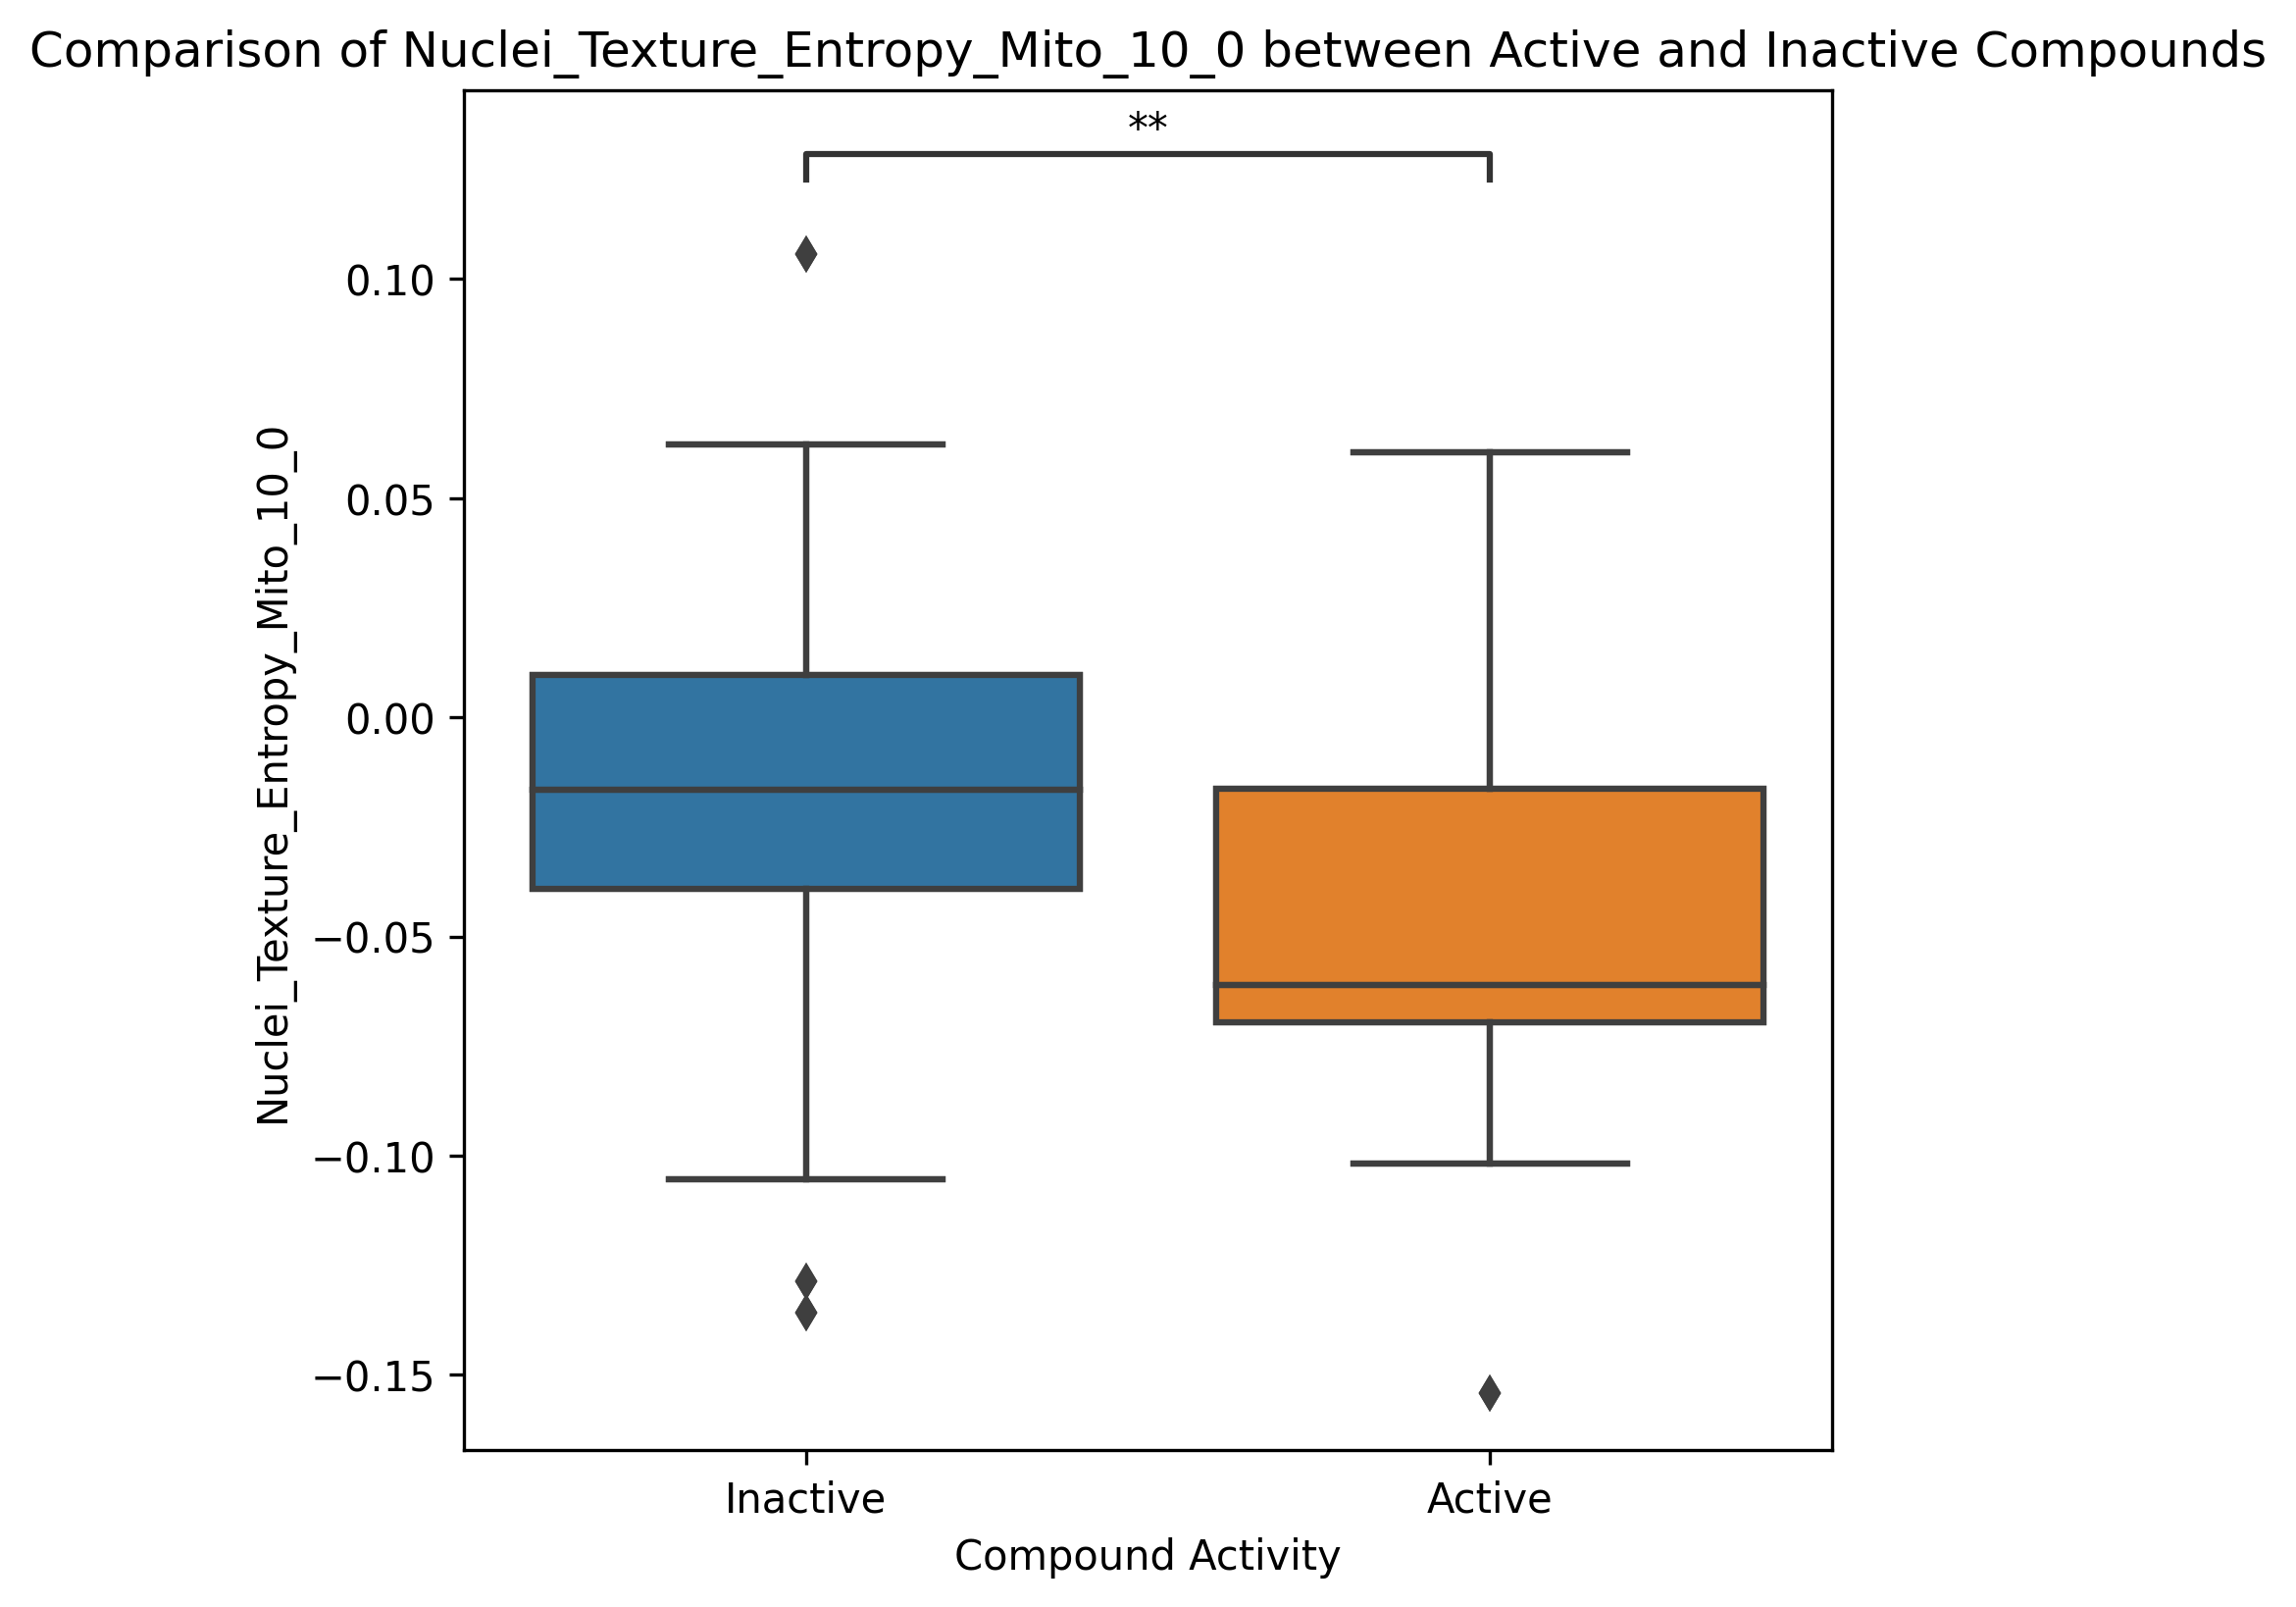

In [21]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statannot import add_stat_annotation


df = RARb_Antagonist
# Convert `CHEMBL5291850` to string for compatibility
df["RARb_Antagonist"] = df["RARb_Antagonist"].astype(str)

# Feature to compare
feature = "Nuclei_Texture_Entropy_Mito_10_0"

# Plot
plt.figure(figsize=(6, 6), dpi=300)
palette = ["#1f77b4", "#ff7f0e"]  # Colors for inactive and active
sns.boxplot(data=df, x="RARb_Antagonist", y=feature, palette=palette)

# Add stat annotation
add_stat_annotation(
    sns.boxplot(data=df, x="RARb_Antagonist", y=feature, palette=palette),
    data=df,
    x="RARb_Antagonist",
    y=feature,
    order=["0.0", "1.0"],  # Use string values matching the converted column
    box_pairs=[("0.0", "1.0")],
    test="Mann-Whitney",
    text_format="star",
    verbose=1,
)

plt.title(f"Comparison of {feature} between Active and Inactive Compounds")
plt.xticks([0, 1], ["Inactive", "Active"])
plt.xlabel("Compound Activity")
plt.ylabel(feature)
plt.show()


p-value annotation legend:
ns: 5.00e-02 < p <= 1.00e+00
*: 1.00e-02 < p <= 5.00e-02
**: 1.00e-03 < p <= 1.00e-02
***: 1.00e-04 < p <= 1.00e-03
****: p <= 1.00e-04

0.0 v.s. 1.0: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val=2.564e-02 U_stat=3.046e+03


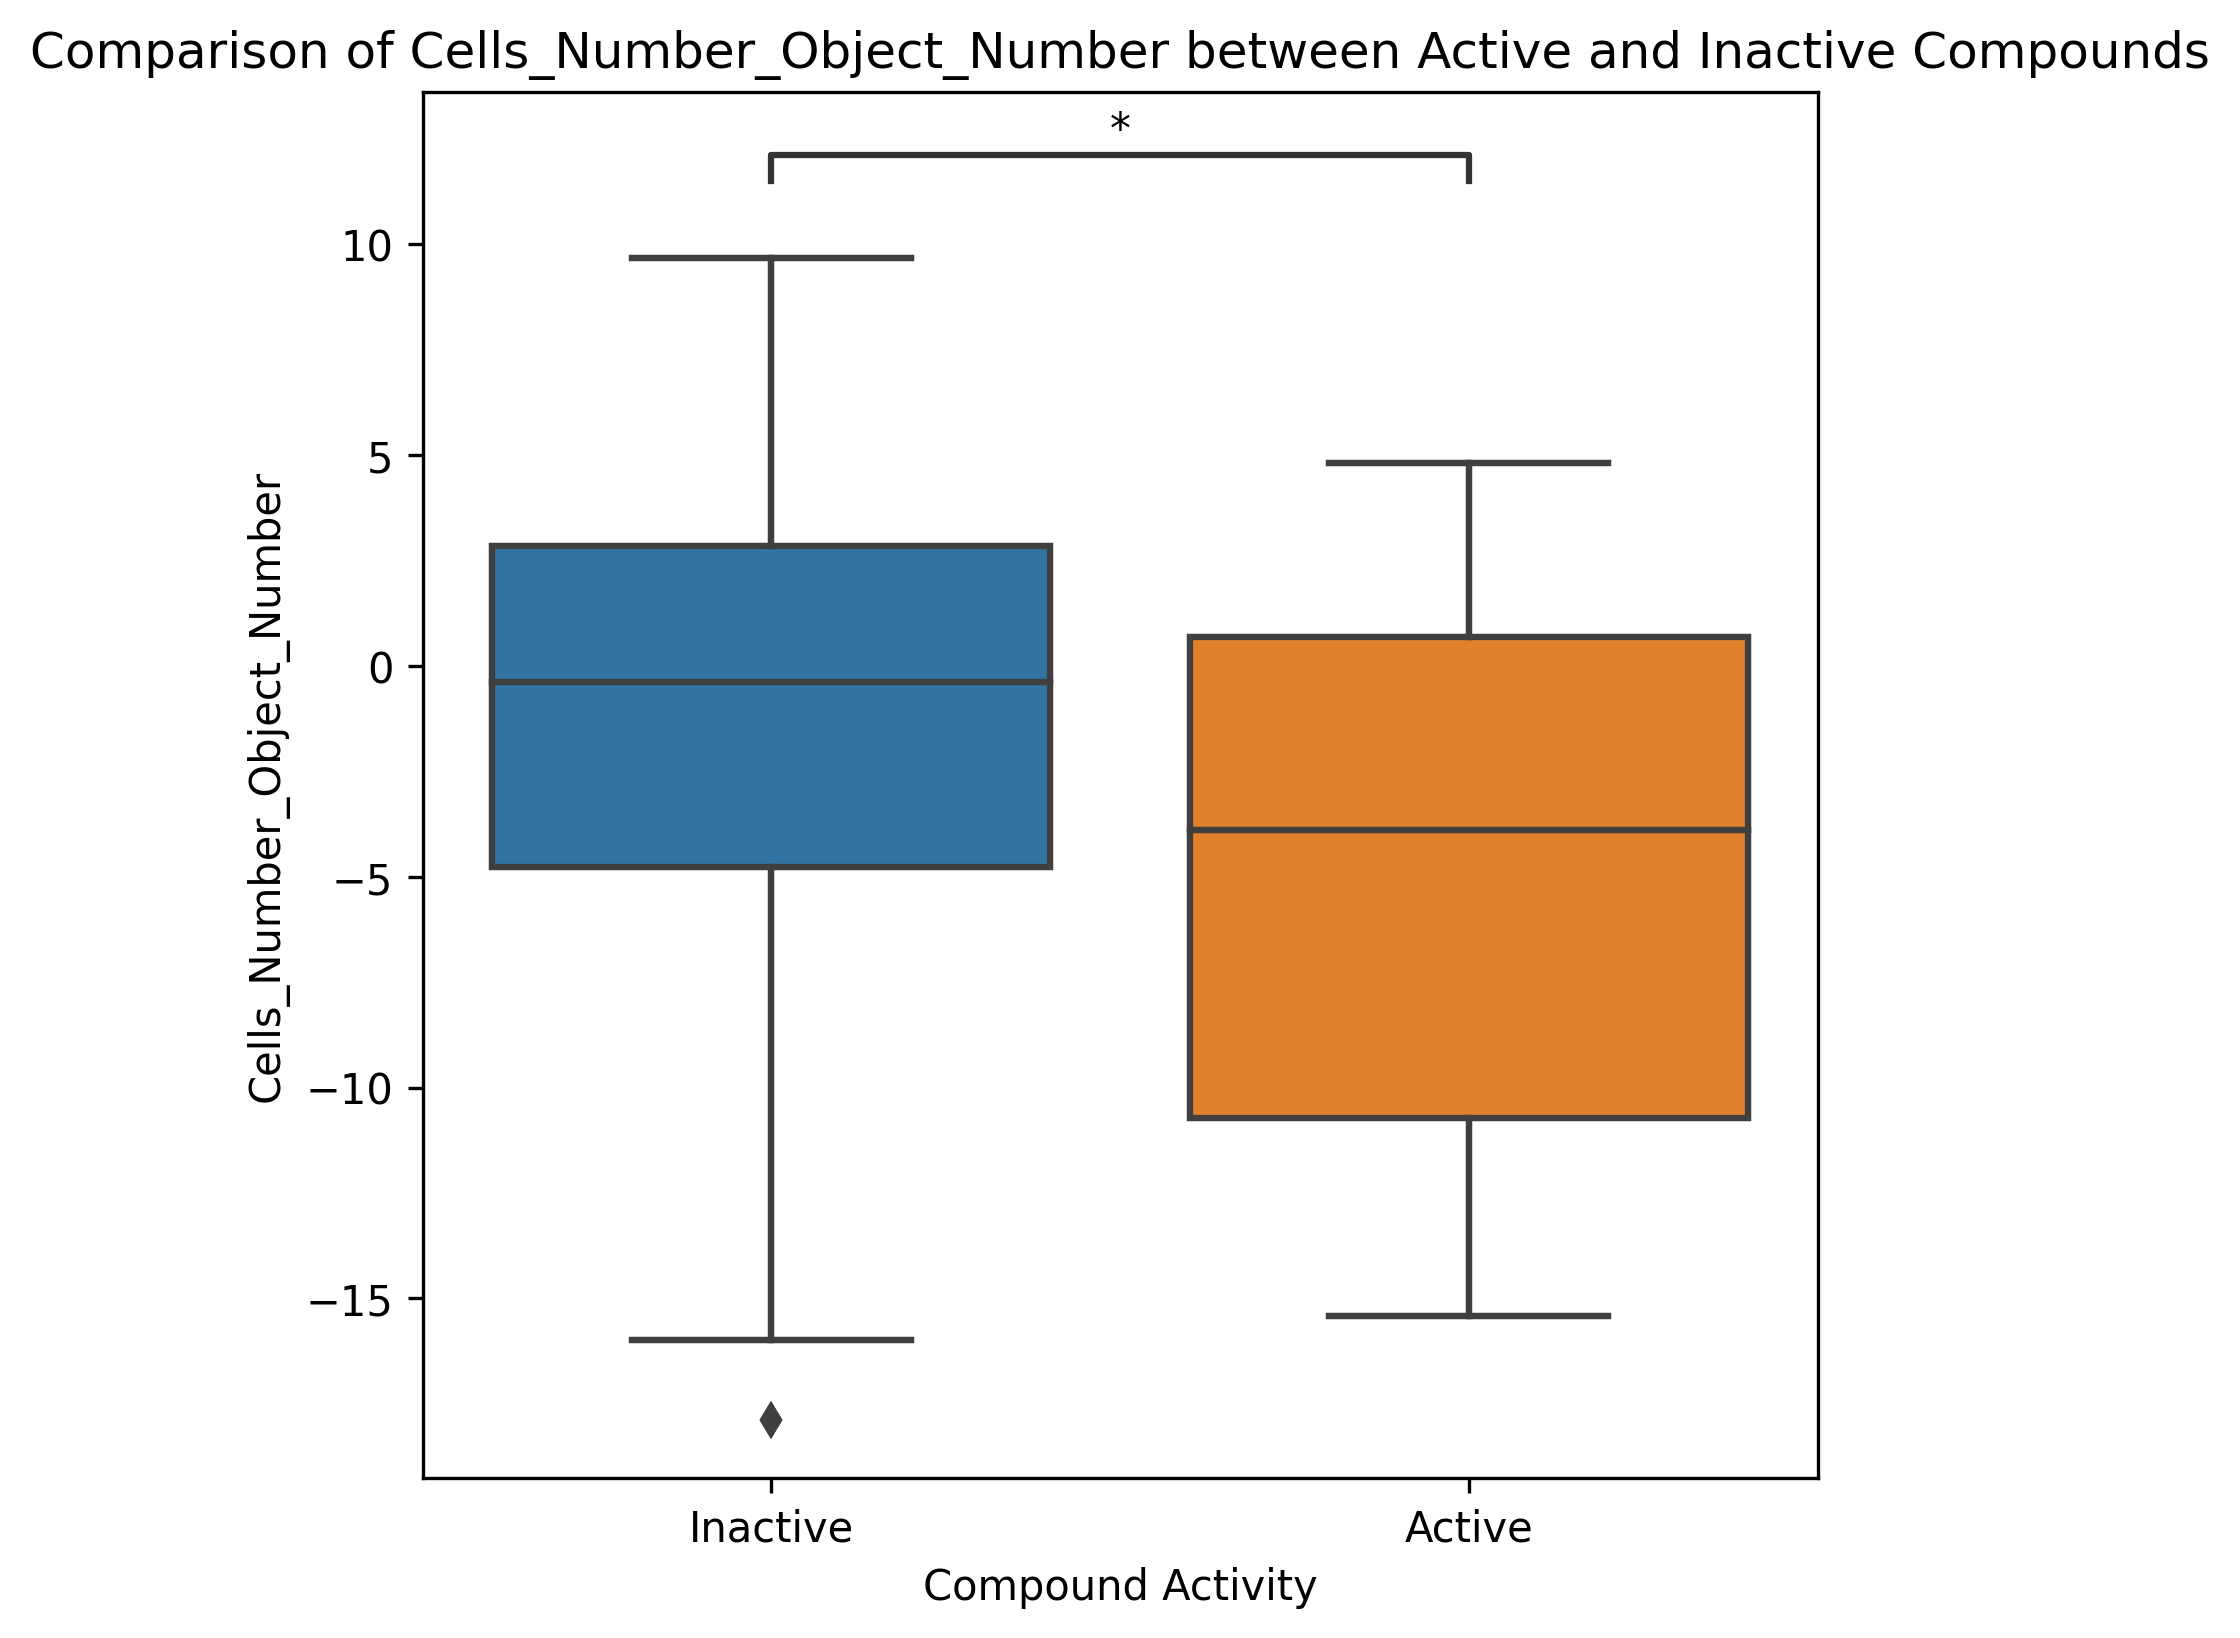

In [22]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statannot import add_stat_annotation


df = RARb_Antagonist
# Convert `CHEMBL5291850` to string for compatibility
df["RARb_Antagonist"] = df["RARb_Antagonist"].astype(str)

# Feature to compare
feature = "Cells_Number_Object_Number"

# Plot
plt.figure(figsize=(6, 6), dpi=300)
palette = ["#1f77b4", "#ff7f0e"]  # Colors for inactive and active
sns.boxplot(data=df, x="RARb_Antagonist", y=feature, palette=palette)

# Add stat annotation
add_stat_annotation(
    sns.boxplot(data=df, x="RARb_Antagonist", y=feature, palette=palette),
    data=df,
    x="RARb_Antagonist",
    y=feature,
    order=["0.0", "1.0"],  # Use string values matching the converted column
    box_pairs=[("0.0", "1.0")],
    test="Mann-Whitney",
    text_format="star",
    verbose=1,
)

plt.title(f"Comparison of {feature} between Active and Inactive Compounds")
plt.xticks([0, 1], ["Inactive", "Active"])
plt.xlabel("Compound Activity")
plt.ylabel(feature)
plt.show()


In [25]:
data[data["GR_Agonist"]==1.0]

,InChIKey,ADRA1A_Antagonist,ADRA2A_Antagonist,ADRA2B_Antagonist,CAR_Antagonist,ERa_Antagonist,ERb_Antagonist,GPR119_Antagonist,GR_Agonist,HCTR1_Antagonist,...,Nuclei_Texture_Variance_DNA_5_0,Nuclei_Texture_Variance_ER_10_0,Nuclei_Texture_Variance_ER_3_0,Nuclei_Texture_Variance_ER_5_0,Nuclei_Texture_Variance_Mito_10_0,Nuclei_Texture_Variance_Mito_3_0,Nuclei_Texture_Variance_Mito_5_0,Nuclei_Texture_Variance_RNA_10_0,Nuclei_Texture_Variance_RNA_3_0,Nuclei_Texture_Variance_RNA_5_0
22,UREBDLICKHMUKA-DVTGEIKXSA-N,1.0,0.0,NaN,0.0,0.0,0.0,1.0,1.0,0.0,...,-0.031132,-0.075174,-0.152182,-0.130762,-0.061754,-0.013278,-0.023806,-0.017246,-0.076933,-0.056217
24,KHOITXIGCFIULA-UHFFFAOYSA-N,1.0,1.0,0.0,0.0,0.0,0.0,NaN,1.0,0.0,...,0.082603,-0.006037,-0.049391,-0.045571,0.000632,-0.007184,0.007416,0.014164,-0.028505,-0.031356
39,JFPVXVDWJQMJEE-IZRZKJBUSA-N,NaN,0.0,0.0,0.0,1.0,1.0,NaN,1.0,0.0,...,0.107921,0.049920,-0.003991,0.039488,0.025037,0.000835,0.007864,0.013899,-0.012813,-0.003175
65,UREBDLICKHMUKA-CXSFZGCWSA-N,1.0,0.0,NaN,0.0,0.0,0.0,0.0,1.0,0.0,...,-0.172436,-0.097026,-0.195676,-0.175980,-0.174115,-0.208546,-0.187752,-0.080060,-0.103896,-0.099231
81,JGMOKGBVKVMRFX-HQZYFCCVSA-N,NaN,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,...,-0.113585,0.049926,0.016710,0.014504,0.034702,0.038910,0.032312,-0.109908,-0.079609,-0.077622
97,WXURHACBFYSXBI-GQKYHHCASA-N,0.0,0.0,NaN,0.0,0.0,0.0,0.0,1.0,0.0,...,0.102156,0.075600,0.055784,0.063449,-0.104831,-0.123773,-0.116617,-0.120055,-0.161249,-0.152733
98,XSFJVAJPIHIPKU-XWCQMRHXSA-N,1.0,0.0,0.0,0.0,0.0,0.0,NaN,1.0,0.0,...,-0.311468,-0.053115,-0.121013,-0.086720,-0.066723,-0.086812,-0.063773,-0.197312,-0.187405,-0.203434
99,WJOHZNCJWYWUJD-IUGZLZTKSA-N,0.0,0.0,0.0,NaN,NaN,NaN,1.0,1.0,0.0,...,0.030594,-0.001682,-0.016622,-0.049083,-0.027226,-0.022548,-0.022349,0.029328,-0.038537,-0.034973
100,FAOZLTXFLGPHNG-KNAQIMQKSA-N,NaN,0.0,0.0,0.0,0.0,0.0,0.0,1.0,NaN,...,-0.258386,-0.094757,-0.098908,-0.087169,-0.125321,-0.141682,-0.115791,-0.117783,-0.121720,-0.105992
101,POPFMWWJOGLOIF-XWCQMRHXSA-N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,NaN,...,-0.202744,-0.029751,-0.072514,-0.066537,-0.148211,-0.195682,-0.157217,-0.158239,-0.205696,-0.183922


In [36]:
eve = pd.read_csv("data/evebio_assay_data_smiles.csv")
# Function to convert SMILES to InChIKey
from rdkit import Chem
from rdkit.Chem import inchi
from pandarallel import pandarallel
pandarallel.initialize()

def smiles_to_inchikey(smiles):
    try:
        mol = Chem.MolFromSmiles(smiles, sanitize=True)
        if mol is None:
            return 'CANNOT_CONVERT'
        # Optionally: kekulize or re-canonize
        Chem.SanitizeMol(mol)
        return inchi.MolToInchiKey(mol)
    except:
        return 'CANNOT_CONVERT'
eve['InChIKey'] =eve['SMILES'].parallel_apply(smiles_to_inchikey)
eve 

INFO: Pandarallel will run on 40 workers.
INFO: Pandarallel will use Memory file system to transfer data between the main process and workers.


,Compound,SMILES,QSAR_READY_SMILES,ADRA1A_Agonist,ADRA1A_Antagonist,ADRA1D_Agonist,ADRA1D_Antagonist,ADRA2A_Agonist,ADRA2A_Antagonist,ADRA2B_Agonist,...,TACR3_Antagonist,TRa_Agonist,TRa_Antagonist,TRb_Agonist,TRb_Antagonist,VDR_Agonist,VDR_Antagonist,rAR_Agonist,rAR_Antagonist,InChIKey
0,"(3R,5R)-Rosuvastatin",NaN,NaN,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,CANNOT_CONVERT
1,"(3R,5S)-Fluvastatin Sodium Salt",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,CANNOT_CONVERT
2,(E/Z)-Belinostat,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,CANNOT_CONVERT
3,"1,2-Diaminocyclohexane",NC1CCCCC1N,NC1CCCCC1N,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,SSJXIUAHEKJCMH-UHFFFAOYSA-N
4,"1,2-Dimyristoyl-Sn-Glycero-3-Phosphocholine",NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,CANNOT_CONVERT
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1392,Zoledronic Acid,O.OC(CN1C=CN=C1)(P(O)(O)=O)P(O)(O)=O,OC(CN1C=CN=C1)(P(O)(O)=O)P(O)(O)=O,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,FUXFIVRTGHOMSO-UHFFFAOYSA-N
1393,Zolmitriptan,CN(C)CCC1=CNC2=C1C=C(C[C@H]1COC(=O)N1)C=C2,CN(C)CCC1=CNC2=CC=C(CC3COC(=O)N3)C=C12,0.0,NaN,0.0,0.0,0.0,0.0,0.0,...,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,ULSDMUVEXKOYBU-ZDUSSCGKSA-N
1394,Zomepirac Sodium Anhydrous,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,CANNOT_CONVERT
1395,Zonisamide,NS(=O)(=O)CC1=NOC2=C1C=CC=C2,NS(=O)(=O)CC1=NOC2=C1C=CC=C2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,UBQNRHZMVUUOMG-UHFFFAOYSA-N


In [38]:
eve_GR = eve[eve.InChIKey.isin(data[data["GR_Agonist"]==1.0].InChIKey.unique())]
eve_GR.Compound.to_list()

['Betamethasone',
 'Bisacodyl',
 'Cefuroxime',
 'Dexamethasone',
 'Dydrogesterone',
 'Flumethasone',
 'Flunisolide',
 'Fluocinonide',
 'Fluorometholone',
 'Flurandrenolide',
 'Fluticasone Propionate',
 'Halcinonide',
 'Hydrocortisone',
 'Medrysone',
 'Methylprednisolone',
 'Pindolol',
 'Prednicarbate',
 'Prednisolone',
 'Progesterone',
 'Terconazole',
 'Triamcinolone',
 'Yohimbine']

In [40]:
eve_RAR = eve[eve.InChIKey.isin(data[data["RARb_Antagonist"]==1.0].InChIKey.unique())]
eve_RAR.Compound.to_list()

['Astemizole',
 'Bithionol',
 'Carvedilol',
 'Clofibric Acid',
 'Felodipine',
 'Imatinib',
 'Ketoconazole',
 'Mifepristone',
 'Nifurtimox',
 'Oxetacaine',
 'Primaquine',
 'Proguanil',
 'Rescinnamine',
 'Salmeterol',
 'Saquinavir',
 'Sertaconazole',
 'Simvastatin',
 'Syrosingopine',
 'Tamoxifen',
 'Terconazole',
 'Triamterene']